In [27]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import corner
import uproot
import pandas as pd
import subprocess

from torch.utils.data import Dataset, DataLoader, random_split

from python.transforms import *
from python.pmssm_dataset import *
from python.load_data import *

In [2]:
# returns the serial number of the gpu with most free memory
def get_free_gpu():
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
        capture_output=True, text=True
    )
    free_mem = [int(x) for x in result.stdout.strip().split("\n")]
    best_gpu = free_mem.index(max(free_mem))
    print(f"Selected GPU {best_gpu} ({free_mem[best_gpu]} MiB free)")
    return best_gpu

In [3]:
# We are only doing analysis in this notebook so cpu is enough
device = "cpu"

### Data loading and preprocessing

In [4]:
parameters_standardized.shape

(9607, 12)

In [11]:
mo_omega_dataset = pMSSM_Dataset(parameters_standardized, mo_omega, device)

Visualize the data $d$ from an arbitrary sample of the `pMSSM_dataset`.

In [12]:
# Get first sample
signal, params = mo_omega_dataset[0]
print(signal)
print(params)

tensor([86.7000])
tensor([ 0.5485,  1.1125, -0.5387,  1.2056, -0.5841,  0.3705,  1.2141, -1.0644,
         0.1646,  0.4739,  0.3704, -0.2141])


/scratch/users/yinya/1.0_toy_model/1.0_toy_model/python/pmssm_dataset.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=self.device), torch.tensor(params, device=self.device)


### Split data into train and test dataset
Determine the number of training and test samples from a `train_fraction` and use the function `random_split()` to separate the data into a training and test dataset. Afterwards define the training and test dataloaders.

In [13]:
num_samples = len(mo_omega_dataset)
train_fraction = 0.8
num_train = int(round(train_fraction * num_samples))
num_test = num_samples - num_train
generator1 = torch.Generator().manual_seed(42)
train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test], generator=generator1)
# train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test])


In the current version (01.06.2026) there is a problem that the RNG seed for random split was not specified for toy models 1-5,
which means we cannot recover the same train test split for the models, and we might be using data for evaluation that was used in training sample.

### Conditional Normalizing Flow
We use the `glasflow` library. It is a wrapper for [`nflows`](https://github.com/bayesiains/nflows), which implements different flow types (e.g. autoregressive flows and coupling flows) and transforms (e.g. rational-quadratic splines).


In [14]:
from glasflow.nflows import distributions, flows

The entire flow model consists of a standard normal base distribution, followed by the flow transform.

In [15]:
transform = create_transform(num_flow_steps = 10,
                             param_dim = np.shape(parameters)[-1],
                             context_dim = np.shape(mo_omega)[-1], #np.shape(data) instead of data.shape to avoid error by one-dim array
                             base_transform_kwargs = {"base_transform_type": "rq-coupling"})

base_distribution = distributions.StandardNormal(shape=[parameters.shape[-1]])

model = flows.Flow(transform, base_distribution)
model = model.to(device)

### Load Weights into the Model

In [16]:
id_training = 6
weights_path = f"../checkpoints/training_{id_training}.pt"
# weights_path = f"../checkpoints/training_{id_training}_epoch_1000.pt"
model.load_state_dict(torch.load(weights_path))

/tmp/ipykernel_888784/2040455866.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(weights_path))


<All keys matched successfully>

### Evaluate the result and visualize posteriors

In [17]:
model = model.eval() #Is equivalent to just "model.eval()", but gets rid of the verbose log

#### Negative Log Likelihood

In [18]:
mo_omega_dataset

In [19]:
dataset = mo_omega_dataset
dataset.parameters.to_numpy().shape
dataset.observables

array([[8.67e+01],
       [1.46e+00],
       [4.00e-03],
       ...,
       [4.37e-02],
       [9.29e-01],
       [1.94e-01]], dtype=float32)

Is the only way to evaluate loss with dataloader? Does the batch_size make sense here?

This way is apparently slower than calculating directly. How to improve?

In [32]:
dataset = mo_omega_dataset
# dataset = train_dataset
# dataset = test_dataset
size = len(dataset)
eval_dataloader = DataLoader(dataset, batch_size=64, shuffle=False)

neg_log_likelihood = 0

with torch.no_grad():
    # X are the parameters and y are the observables
    for X, y in eval_dataloader:
        loss = - model.log_prob(y, X)
        neg_log_likelihood += loss.sum()

    neg_log_likelihood = neg_log_likelihood.item() / size
    print(f"Negative Log Likelihood: {neg_log_likelihood:>8f} \n")



/scratch/users/yinya/1.0_toy_model/1.0_toy_model/python/pmssm_dataset.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=self.device), torch.tensor(params, device=self.device)


Negative Log Likelihood: 14.651211 



In [31]:
dataset = mo_omega_dataset
size = len(dataset)

nll = - model.log_prob(dataset.parameters.to_numpy(), dataset.observables).sum() / size
print(nll)

tensor(14.6512, grad_fn=<DivBackward0>)


#### Choose data points randomly

/tmp/ipykernel_20905/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  axes[k1, k1].axvline(xs[k1], **kwargs)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:849: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with D

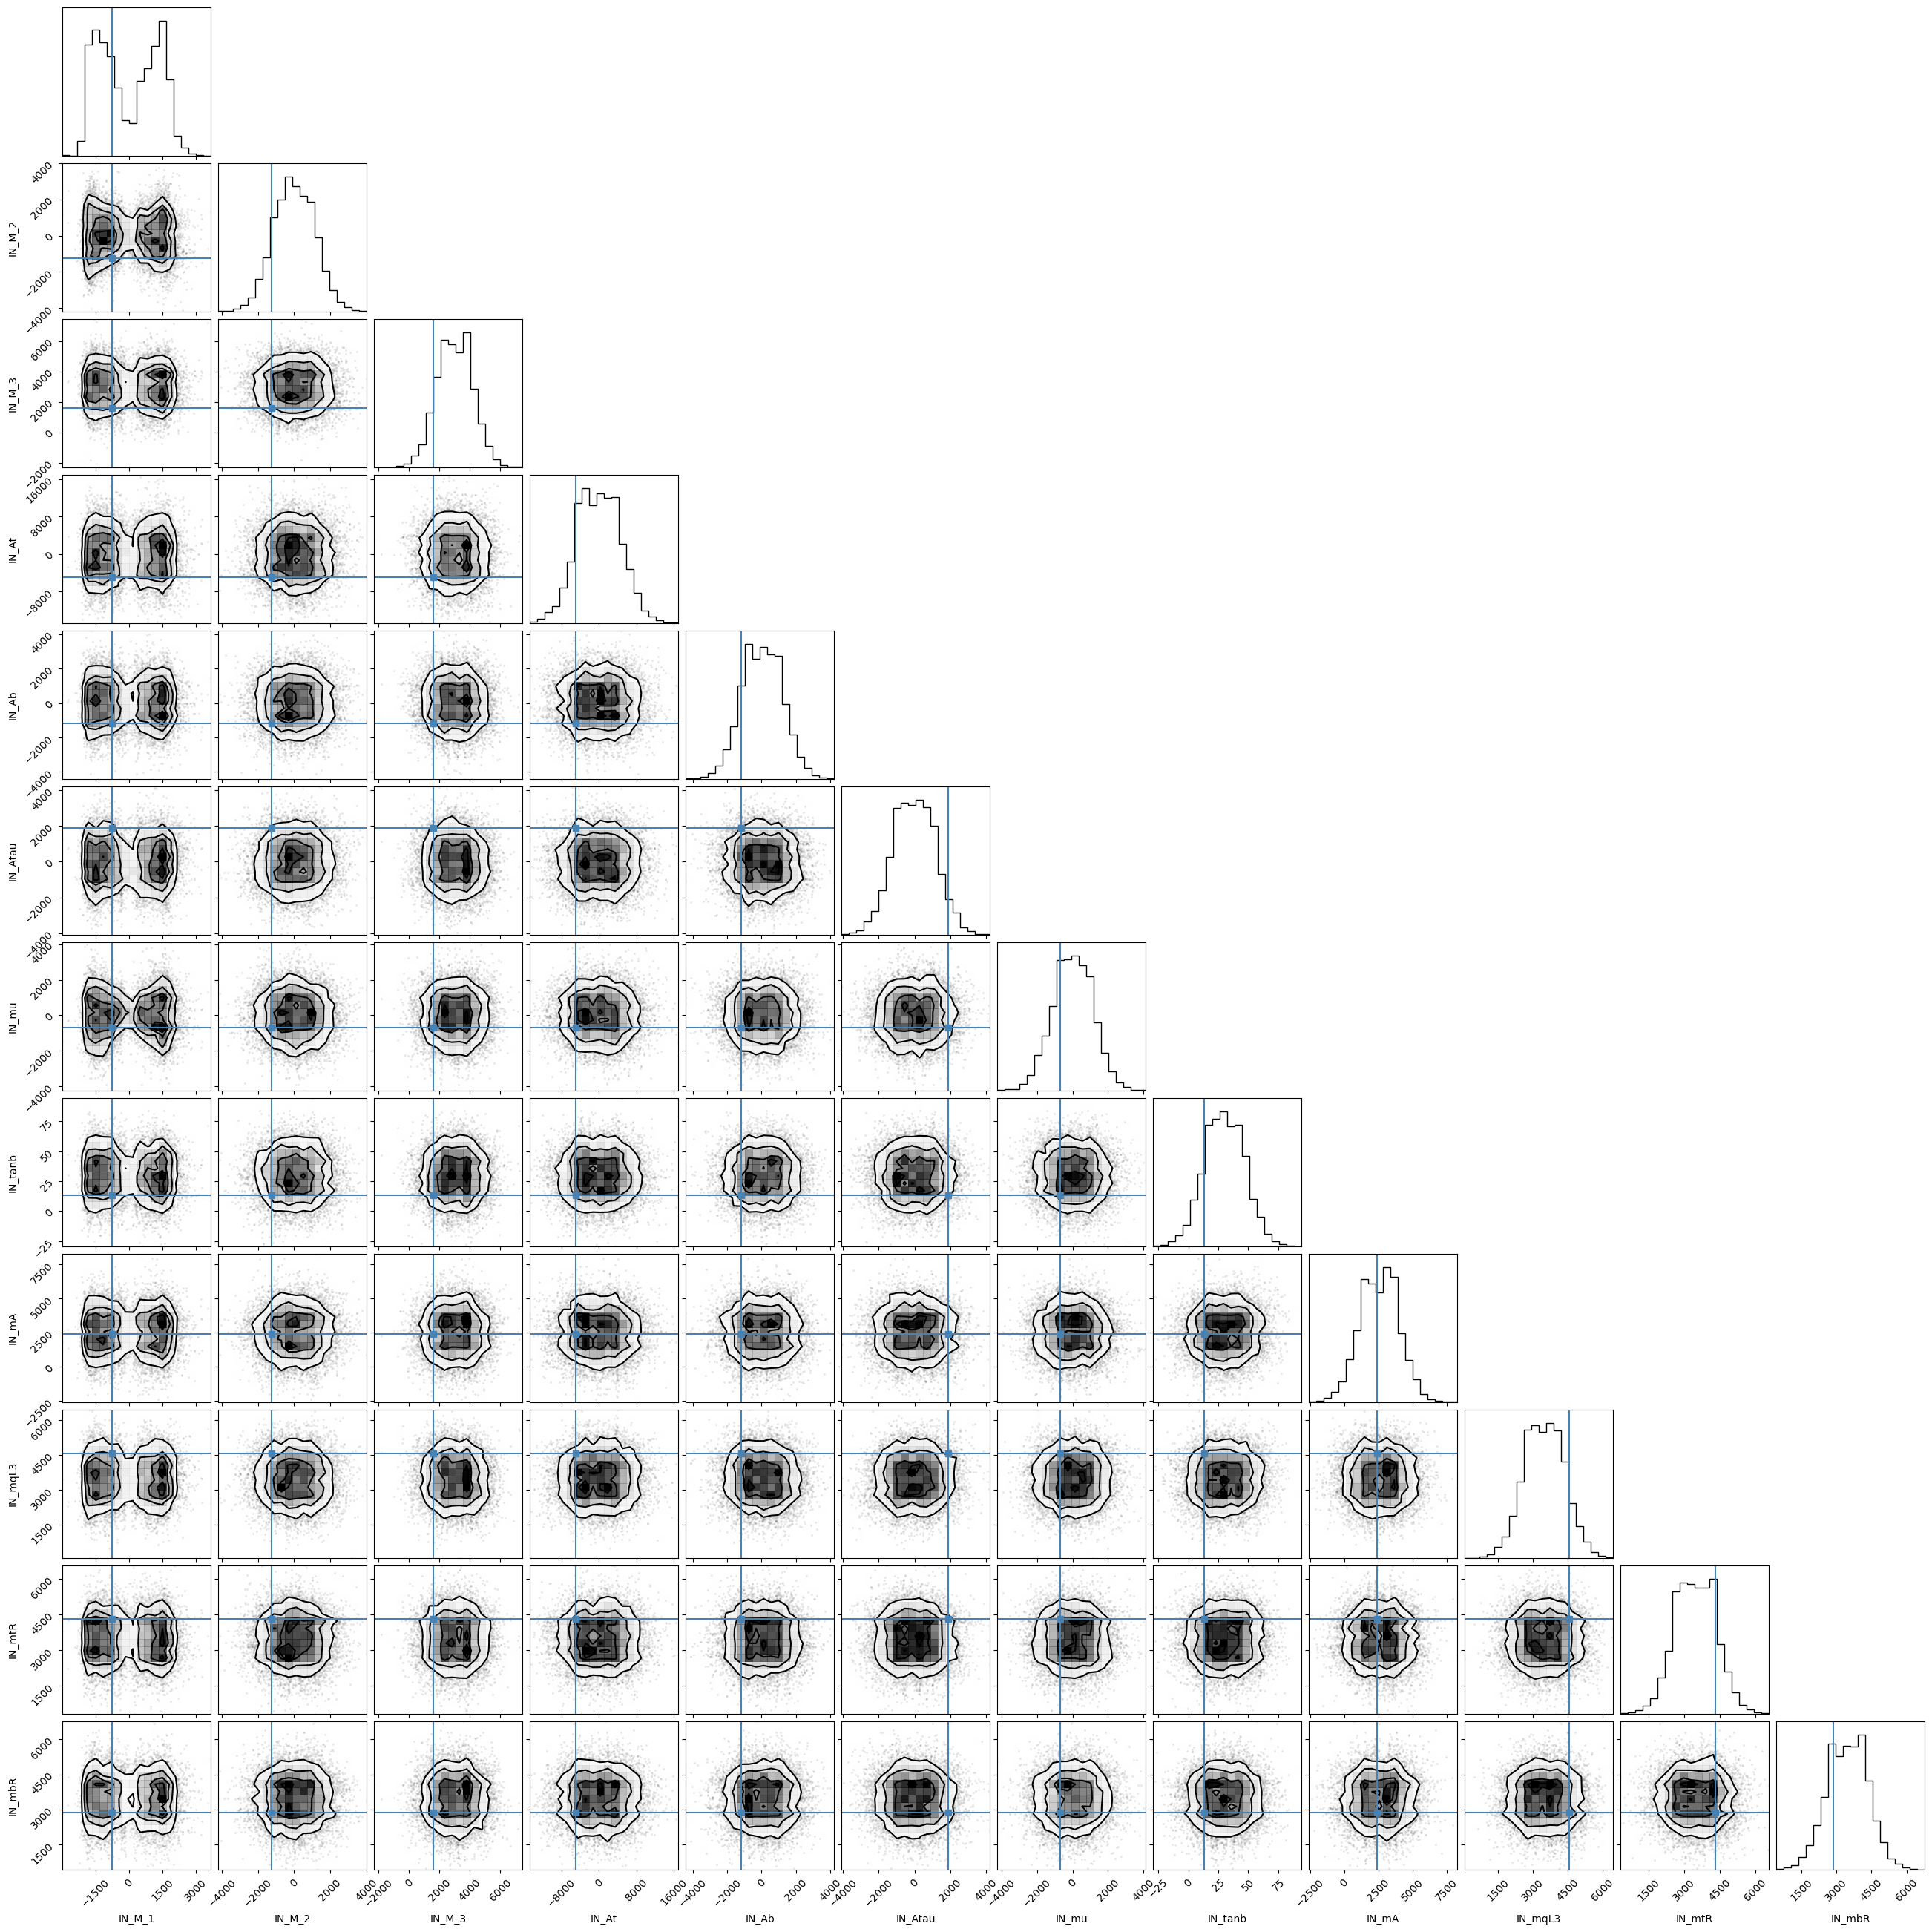

/tmp/ipykernel_20905/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To acc

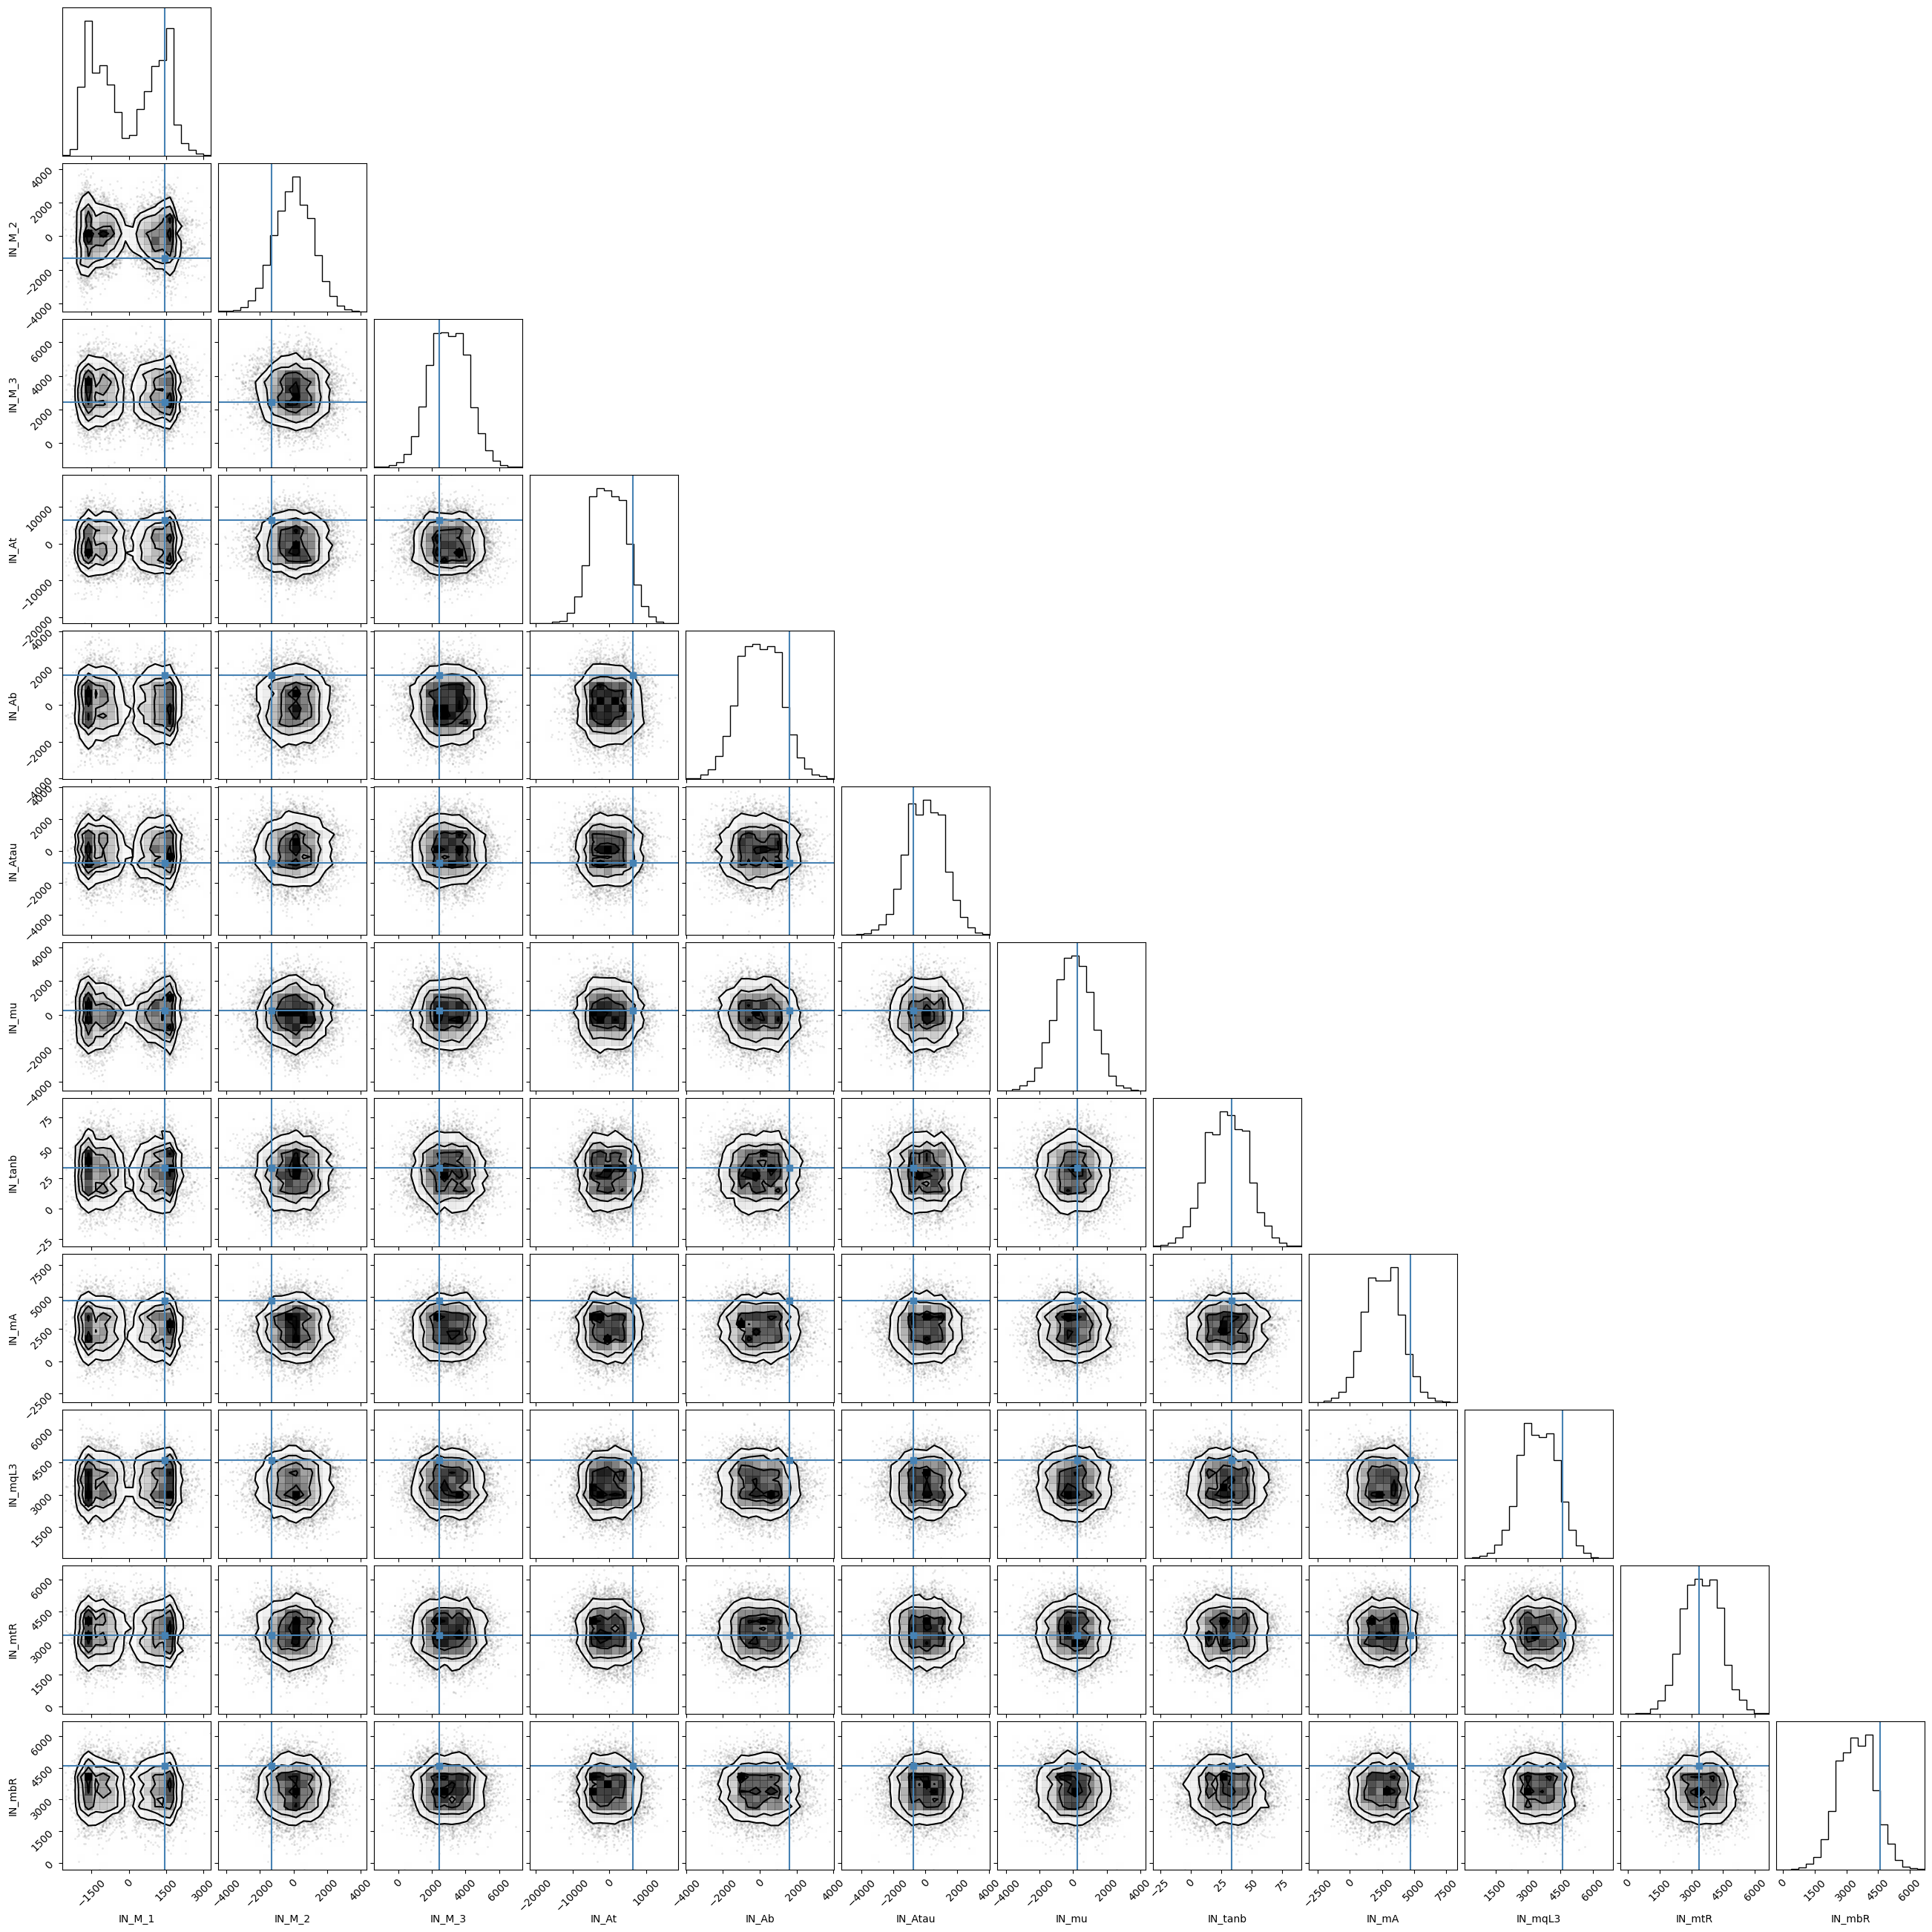

/tmp/ipykernel_20905/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To acc

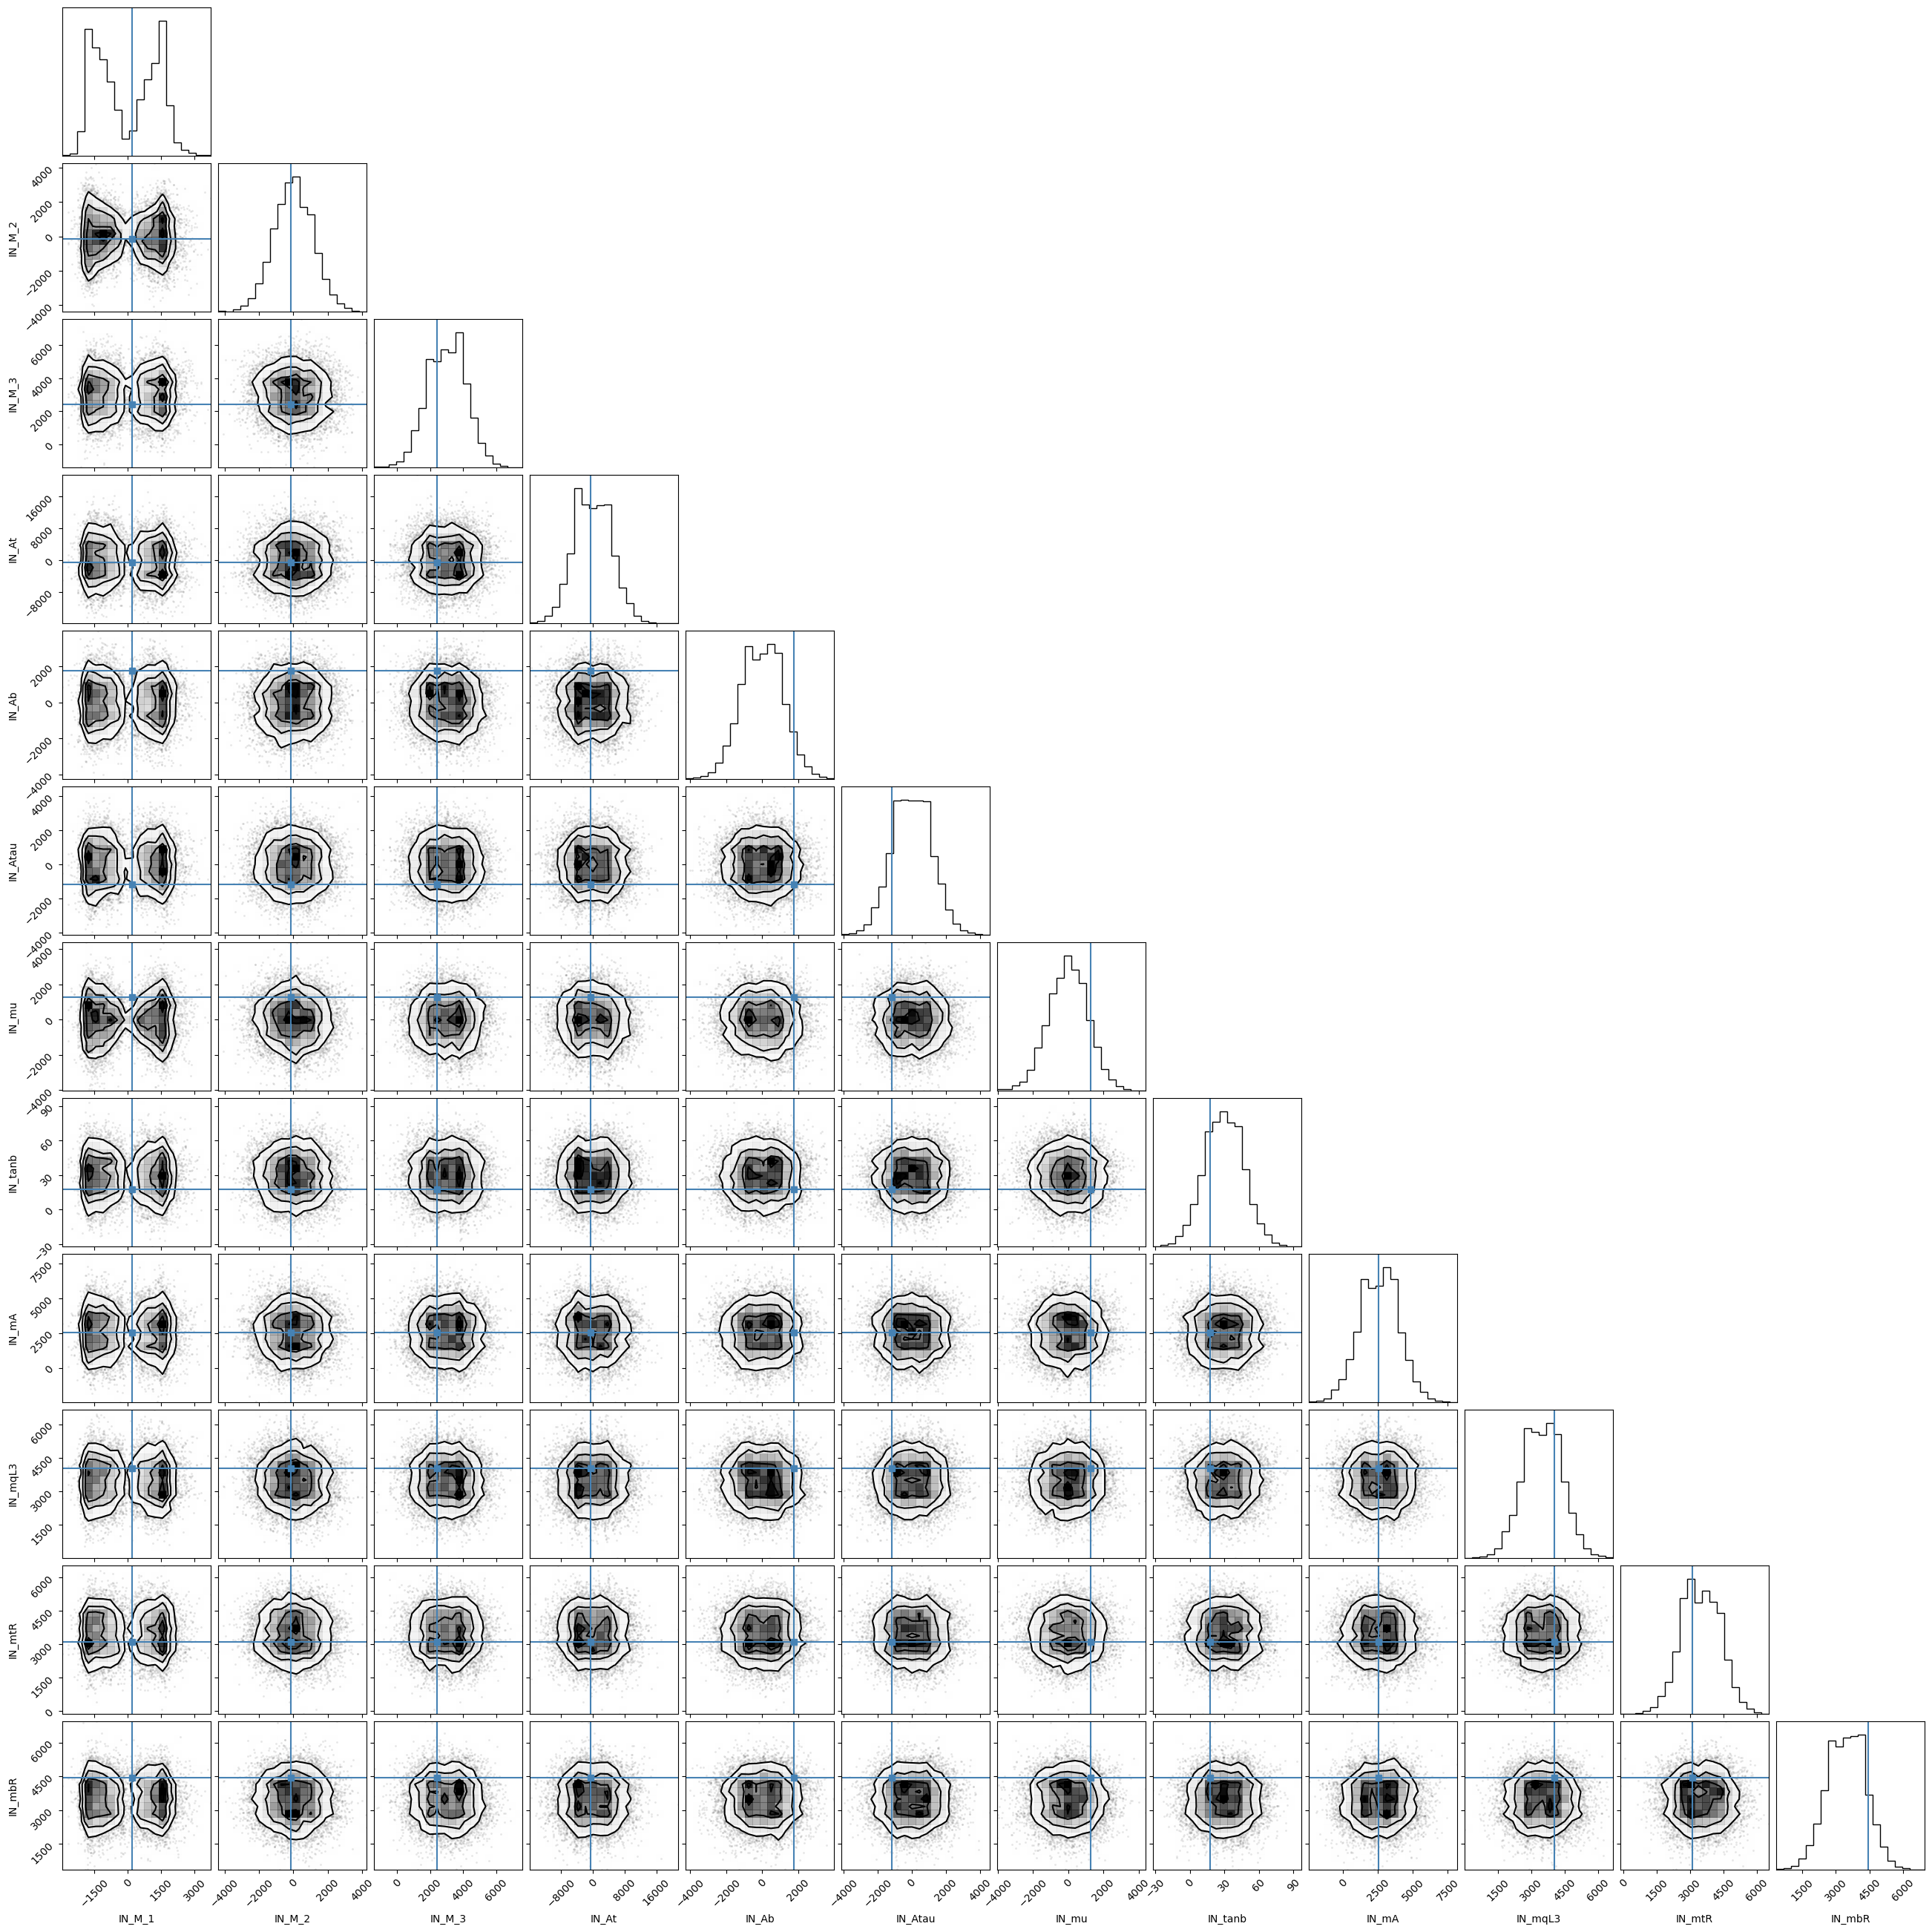

In [ ]:
num_posteriors = 3
num_eval_samples = 10_000

model.eval()

for n in range(num_posteriors):

    with torch.no_grad():
    
        test_x, test_y = test_dataset[n]
    
        # Sample the posterior
        test_x = test_x.expand(num_eval_samples, *test_x.shape)
        pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()
    
        # Undo the standardization
        pred_samples = parameters_std.to_numpy() * pred_samples + parameters_mean.to_numpy()
        truth = parameters_std * test_y.cpu().numpy() + parameters_mean
    
        # Plot
        corner.corner(pred_samples, truths=truth, labels=theory_param_nonconst)
        plt.show()

#### Use data points closest to chosen observables

In [24]:
# test_dataset[0]
# import torch
# from torch.utils.data import DataLoader

def find_closest(dataset, target: float):
    """
    Returns the dataset item whose first tensor entry is closest to `target`.
    
    Args:
        dataset: A PyTorch Dataset where each item is (scalar_tensor, feature_tensor)
        target:  The float value to search for
    
    Returns:
        (best_item, best_idx, best_diff) – the matching item, its index, and the absolute difference
    """
    target_t = torch.tensor(target)
    best_idx  = None
    best_diff = float("inf")

    for idx in range(len(dataset)):
        item = dataset[idx]
        diff = (item[0] - target_t).abs().item()
        if diff < best_diff:
            best_diff = diff
            best_idx  = idx

    return dataset[best_idx], best_idx, best_diff

In [26]:
dataset_cl, idx_cl, diff_cl = find_closest(test_dataset, 10)
dataset_cl

/tmp/ipykernel_20905/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


(tensor([10.2000]),
 tensor([ 0.2559, -0.6166,  0.9793,  0.9481,  1.0425, -0.6284,  0.5859,  1.5250,
         -0.1821,  0.6291, -0.2992,  0.6874]))

/tmp/ipykernel_20905/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To acc

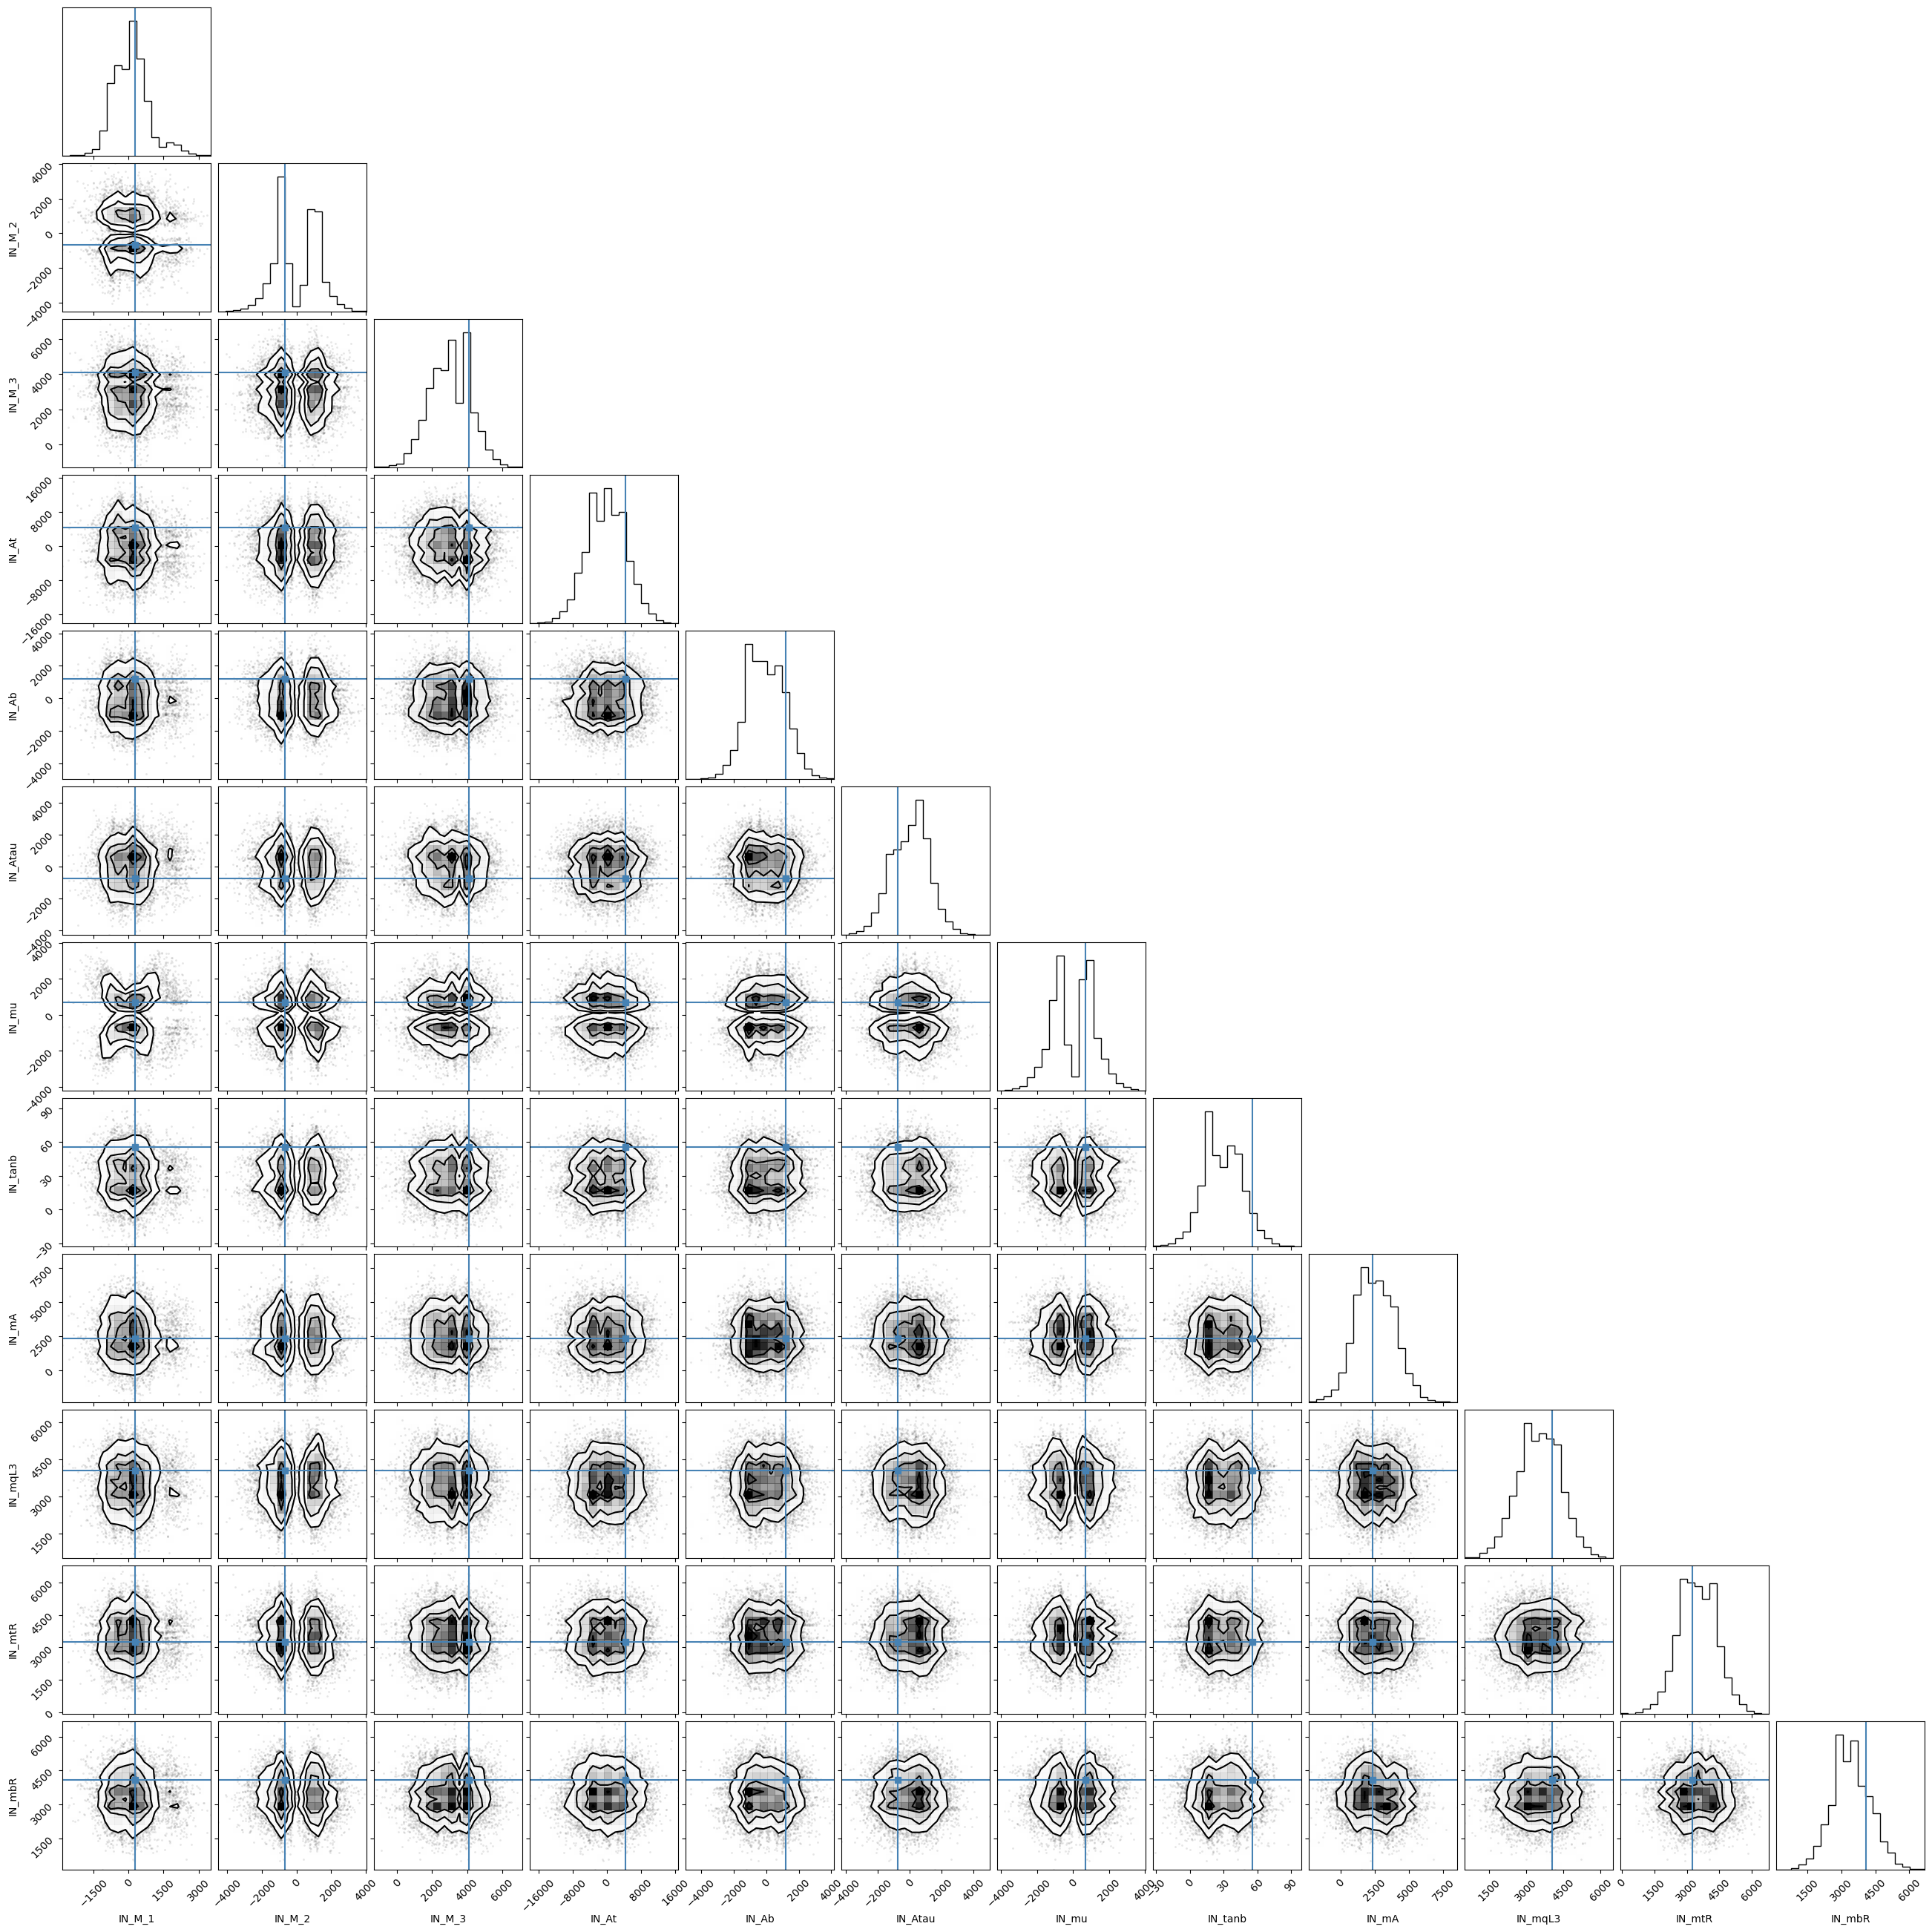

In [27]:
with torch.no_grad():

    test_x, test_y = test_dataset[idx_cl]

    # Sample the posterior
    test_x = test_x.expand(10000, *test_x.shape)
    pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()

    # Undo the standardization
    pred_samples = parameters_std.to_numpy() * pred_samples + parameters_mean.to_numpy()
    truth = parameters_std * test_y.cpu().numpy() + parameters_mean

    # Plot
    corner.corner(pred_samples, truths=truth, labels=theory_param_nonconst)
    plt.show()